# Marine gravity currents on a passive margin

Rivers deliver most of their load to the coast, where goSPL's clinoform scheme builds a prograding wedge of topsets and foresets. Part of the load, however, does not settle there: during floods, sediment-laden river water plunges as **hyperpycnal flows**, and failures on the delta front generate **turbidity currents**. These gravity currents cross the shelf and the slope and build coarse-grained bodies at the foot of the slope and finer lobes on the basin floor.

goSPL's optional `gravity:` block adds this second pathway. The currents are not resolved as flows (a turbidity-current model needs time steps of seconds); a fraction of the river load is instead **routed down the seafloor** and deposits gradually over a **run-out length**:

$$\left(I - W^T \mathrm{diag}(1 - \Lambda)\right) q = s, \qquad D_i = \Lambda_i q_i, \qquad \Lambda_i = \left(1 - e^{-\ell_i / L}\right) T_d(d_i)\, T_S(S_i)$$

with $s$ the diverted supply, $W$ the receiver weights of the seafloor network, $q$ the flux, $\ell_i$ the cell size, $L$ the run-out length, and $T_d$, $T_S$ smooth tapers that make the currents bypass the shelf (water shallower than `bypass_depth`) and the steep foresets (`bypass_slope`). The system is linear, solved once per step and grain fraction, and conserves volume exactly (supplied = deposited + exported). The equations and every parameter are described in the goSPL technical and user guides (*Gravity currents*).

This example runs the margin of the [`dual_lithology`](../dual_lithology) example (200 x 100 km, 615 m cells, coarse and fine sediment, falling and oscillating sea level, flexure) for 250 kyr, **with and without** gravity currents, and compares the surface, the deposits and the stratigraphy.

## Running the simulations

The mesh and the sea-level curve are in `data/` (the same files as in `dual_lithology`). The example needs a goSPL with the gravity-current module (the `environment.yml` of this branch builds it).

```bash
./run_all.sh     # both runs (4 ranks each, a few minutes)
# or one run:
mpirun -np 4 gospl -i input-gravity.yml --summary summary_gravity.jsonl
```

`input-gravity.yml` differs from `input-nogravity.yml` only by its `gravity:` block:

```yaml
gravity:
    fraction: 0.3         # 30 % of the river load reaching the sea becomes gravity currents
    coarse_factor: 0.3    # ... but only 0.3 x that for the coarse load (mostly suspended load)
    runout: 1.e4          # coarse run-out length (m)
    runout_fine: 2.e4     # fine run-out length (m)
    bypass_slope: 0.01    # less deposition on the foresets (bypass_depth: 50 m by default)
    receivers: 2          # coarse network: concentrated pathways (belts)
    flow_exp: 4.
    receivers_fine: 6     # fine network: spreading (lobes)
    flow_exp_fine: 1.
    network_smooth: 3     # smoothing passes of the routing surface
    slope_smooth: 3       # smoothing passes of the slope used by the tapers
    deposit_spread: 1500. # lateral spreading of each step's deposit (m)
```

Run side by side with 4 ranks each on a laptop, the 50 steps take 97 s with gravity currents and 79 s without (`log_*.txt`).

In [1]:
import matplotlib.pyplot as plt
%matplotlib inline

from scripts import gravity

STEP = gravity.last_step("sim_gravity")   # 25: 250 kyr (outputs every 10 kyr)
print("output step", STEP)

output step 25


## Gravity budget

With `--summary`, every step's record carries the gravity budget: the volume supplied to the currents, the volume they deposit and the volume they export through the open boundaries (and the volume eroded, when slope erosion is on). The budget closes to the solver tolerance.

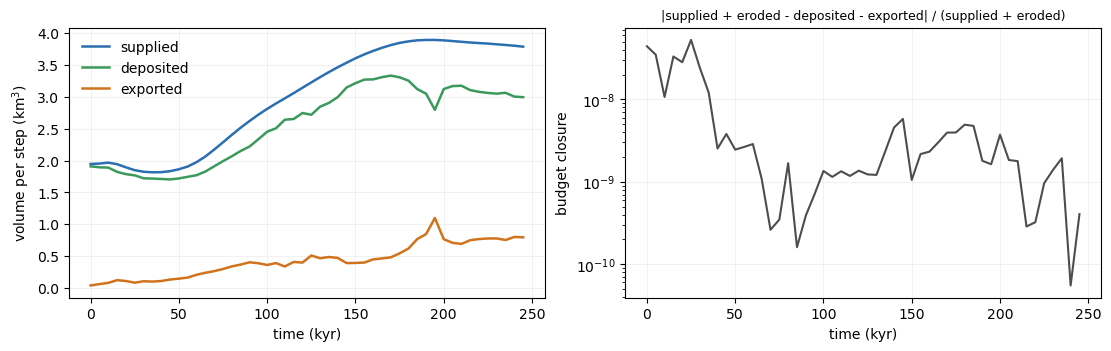

In [2]:
fig = gravity.budget("summary_gravity.jsonl")
plt.show()

## Map views

Top: the margin without gravity currents. The clinoform wedge ends at the foot of the slope and the basin floor receives nothing. Bottom: with gravity currents, sediment bypasses the shelf and the foresets and spreads over the basin floor (middle panel). The coarse load follows the concentrated network and stays nearer the slope base; the fine load, on its spreading network with a longer run-out, goes further. With `coarse_factor: 0.3` the gravity deposits are mixed (fine fraction about 0.4 to 0.6 near the slope base), get finer basinward, and keep finer streaks between the main pathways (right panel).

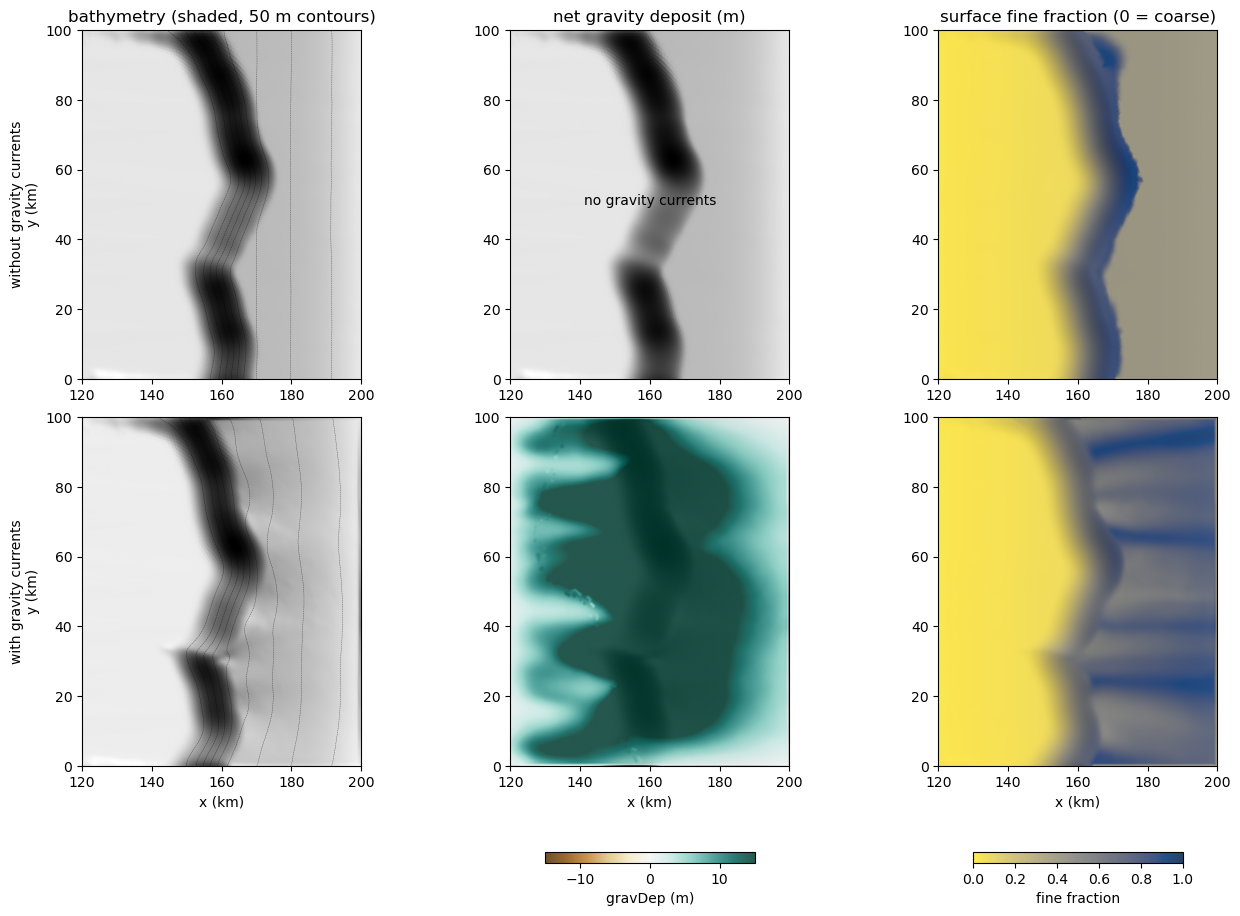

In [3]:
fig = gravity.maps(STEP)
plt.show()

## Strike sections

Profiles along the margin (along $y$) every 10 km from the shelf (130 km) to the basin floor (190 km). Left: elevation (dashed: initial surface). Right: cumulative deposit (solid) and flexural displacement (dotted). The elevation of the basin floor drops by 30 to 50 m in both runs: that is the flexural subsidence under the sediment load, not erosion. Beyond the toe of the clinoforms (about 175 km) only the run with gravity currents deposits.

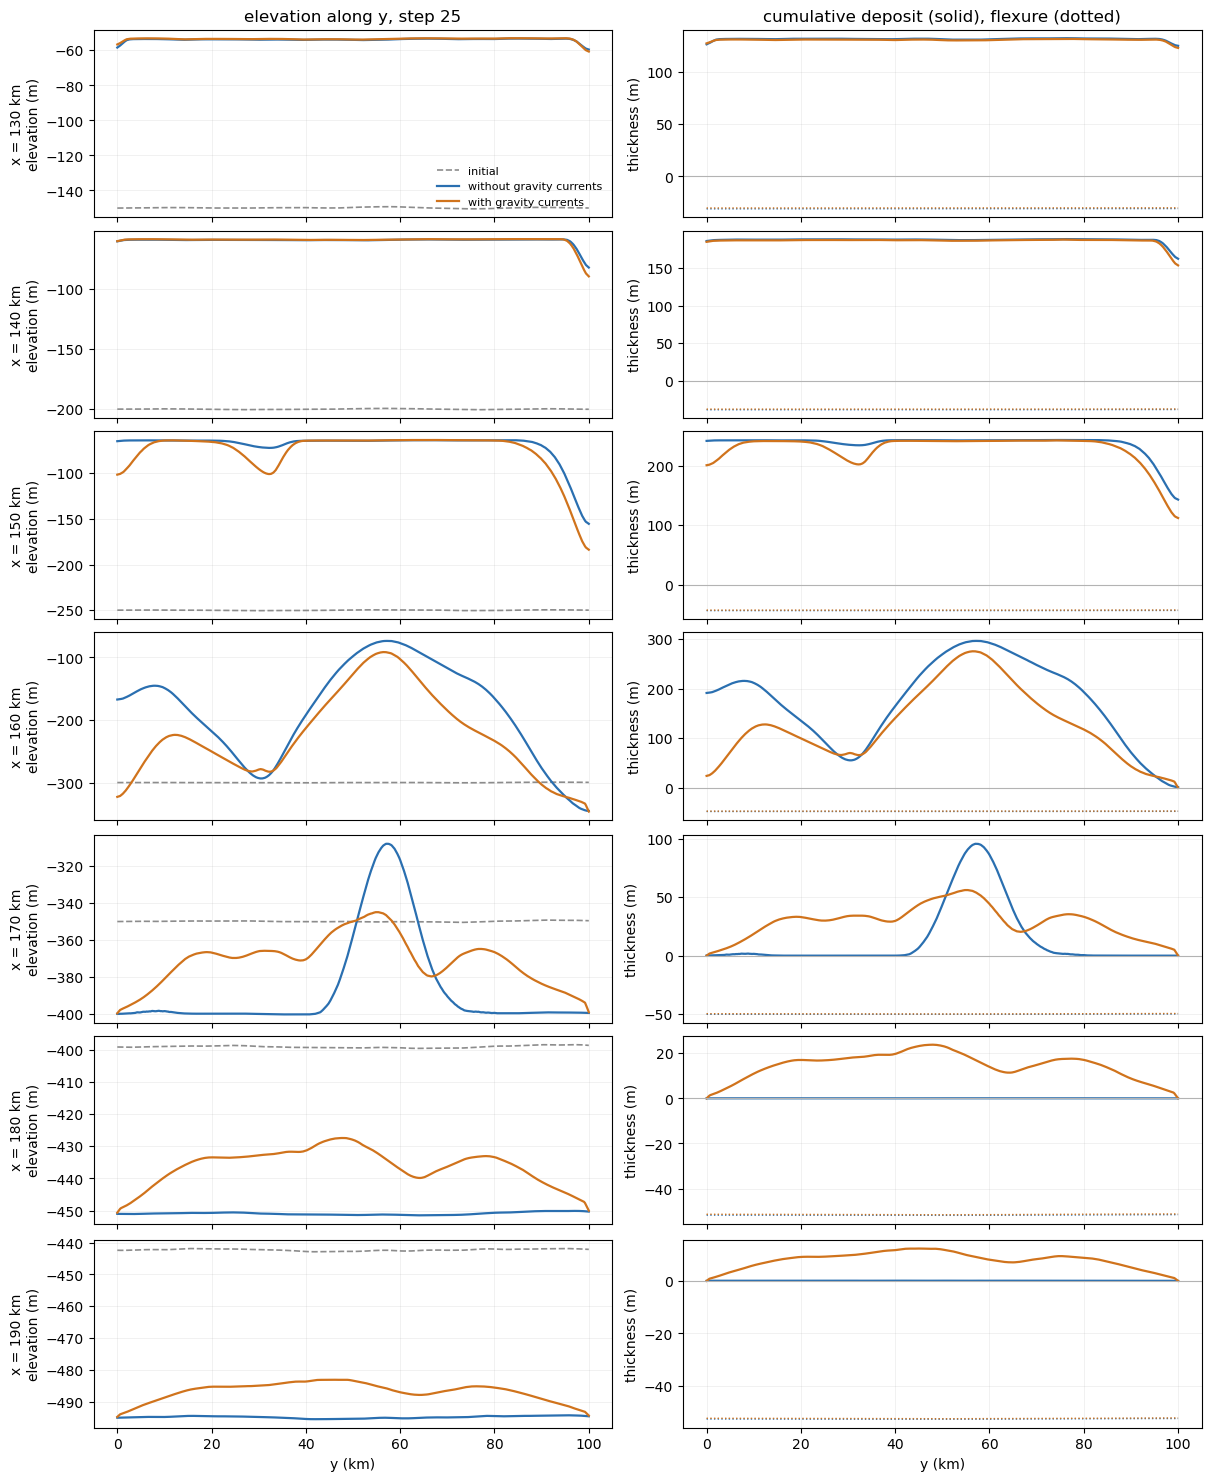

In [4]:
fig = gravity.strike_sections(STEP)
plt.show()

## Stratigraphy

Dip sections (along $x$) at three positions along the margin, each layer coloured by its fine fraction. Without gravity currents the clinoforms have coarse topsets and fine toesets and stop at 165 to 175 km. With them, continuous bottomset layers extend from the slope toe to the basin floor: mixed near the toe (fine fraction 0.5 to 0.7) and fine downdip (about 0.9).

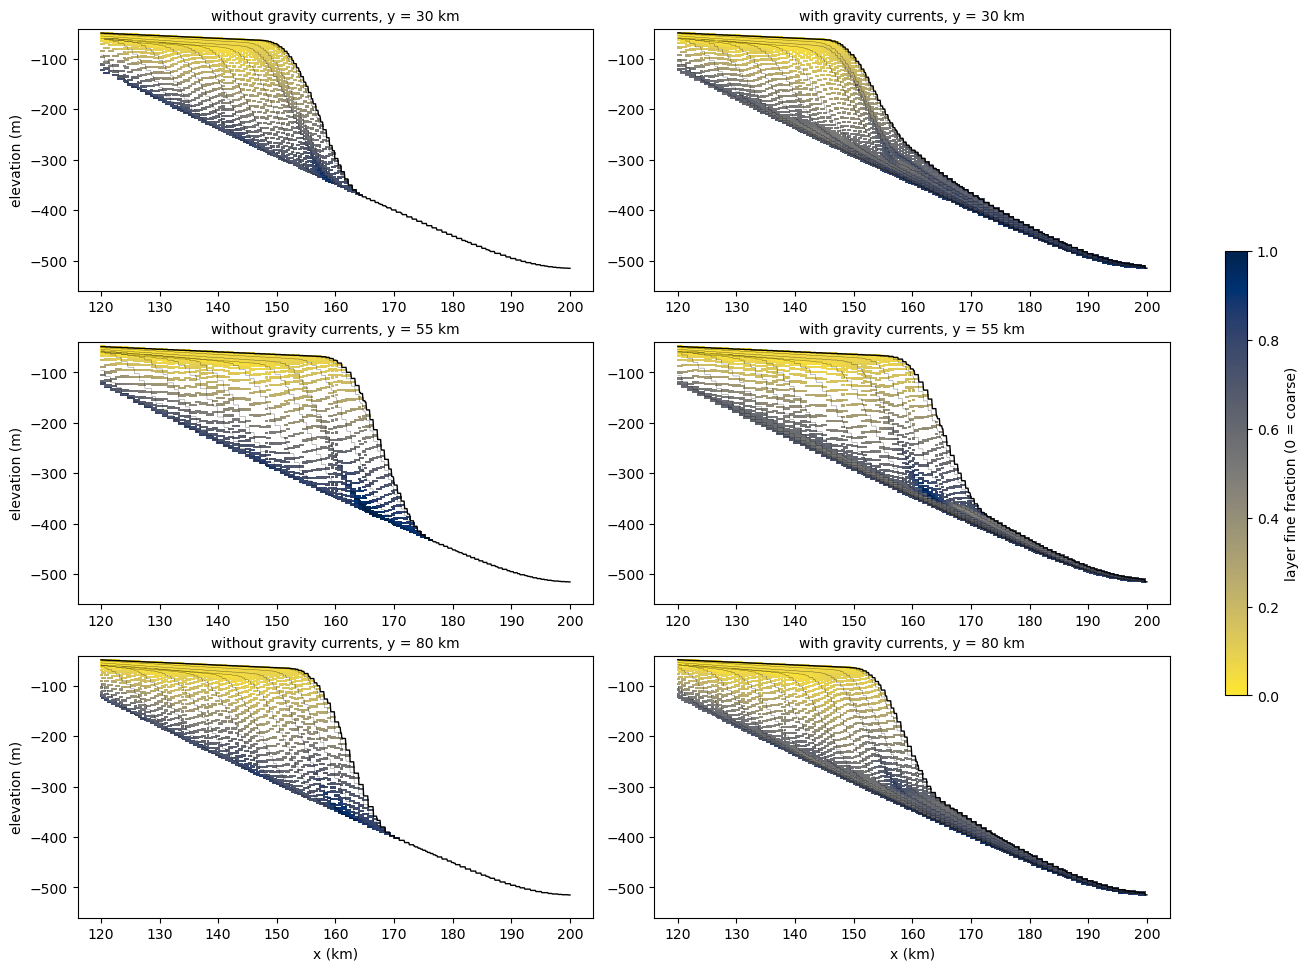

In [5]:
fig = gravity.dip_sections(STEP)
plt.show()

## Things to try

- Replace `fraction: 0.3` by a `flood:` block (`sigma: 2.` for flashy rivers) to compute the fraction from floods above the hyperpycnal threshold.
- Set `coarse_factor: 1.`: as much coarse as fine is diverted and thick coarse lobes build at the foot of the slope.
- Remove `deposit_spread`: the concentrated coarse network then builds ridges one cell wide.
- Lengthen the run-outs to move the deposits further into the basin.

Slope erosion by the currents (`erosion_length`) is left off: at this resolution (615 m cells, 5 kyr steps) channels are not resolved and erosion mostly roughens the toe of the slope. See the goSPL user guide (*Marine gravity currents*) for the cautions.